# Description

Training for analyzing Octopus-slabs database with Pandas


# Page usage

* Checking how many entries we have with a certain filter.  


# Loading library

In [1]:
import pandas as pd
import octopus_slabs
from octopus_slabs.Libs.libPlotting import IndexFunctional
import os
import matplotlib.pyplot as plt
import numpy as np
OctopusData=os.environ["QuantumLaPruns"]
OctopusSources=os.environ["QuantumLaPsources"]
print(OctopusData, OctopusSources)

/home/thibault.derrien/Documents/octopus.data /home/thibault.derrien/Documents/octopus-slabs


# Going to the folder containing the database

In [2]:
# Localhost
# DatabasePath=OctopusData+"/03-Bulk3D/Si-1x1x1-k-24x24x1-Mesh0.434637008855-Mesh0.434637008855-T0e0-TB09/SingleColorSummary"

# BIATRI-SRV TB09 from backups (Draco, etc)
# DatabasePath=OctopusData+"/03-Bulk3D/01-ImportingTB09"

DatabasePath=OctopusData+"/03-Bulk3D/"
# DatabasePath=OctopusData+"/09-Au/"
%cd $DatabasePath

/home/thibault.derrien/Documents/octopus.data/03-Bulk3D


# Database loading and quick analysis

In [3]:
data=pd.read_csv("SiComplete-2021-12-19-BiatriSrv-v2.2.1-WithToleranceOnField-WithAll.csv", "\t", header=2)
# data=pd.read_csv("2021-02-25-Au-AllData-Database-v2.1.2.csv", "\t", header=2)
data=pd.read_csv("SiComplete-2022-01-16-BiatriSrv-v2.2.1-WithToleranceOnField-WithAll.csv", "\t", header=2)
data.describe(include="all")
data=data.rename(columns={"##JobID": "JobID"})
data=data.convert_dtypes()
print(data.dtypes)
datafull=data

JobID                             Int64
RunDate                           Int64
kgrid                             Int64
realmesh                        float64
lambda1                         float64
tau1                            float64
Efield1                           Int64
PolarizationAngle               float64
CEP1                            float64
lambda2                         float64
tau2                            float64
Efield2                           Int64
CEP2                            float64
delay                           float64
CrossPolar                      float64
TheoryLevel                       Int64
InducedFields                     Int64
ProbeFieldAmplitude_AU            Int64
ProbeFieldDelay_s               float64
Functional                        Int64
FrozenHxc                         Int64
MoveIon                           Int64
NeMax                           float64
NeFinal                         float64
VirtualOscillations             float64


# Database filtering

In [4]:
data=datafull
data=data[data.Functional==IndexFunctional["LDA"]] #0: LDA, #3: TB09, #2: GGA, #1: MGGA
data=data[data.kgrid>=40]
data

,JobID,RunDate,kgrid,realmesh,lambda1,tau1,Efield1,PolarizationAngle,CEP1,lambda2,...,ExchangeEnergy_afterpulse_eV,PoyntingEnergyFinal_eV,Eext_peak_V_m,N_exc_afterpulse,Wpi,Wpi_afterpulse,STH,RiseCycles,FinalTime,CaptureTime
2491,586197,20211221,40,0.434637,0.000003,1.394500e-14,3000000000,0.753982,0.0,0.000003,...,0.052258,0.329695,-6.911429e+14,2.473146e+27,1.773881e+41,1.773500e+41,1,0,1875.0,1153.010893
2492,528466,20210929,40,0.434637,0.000003,1.394500e-14,3000000000,0.125664,0.0,0.000003,...,0.045713,0.476599,1.057210e+15,2.018731e+27,1.447718e+41,1.447638e+41,1,0,1250.0,1153.010893
2493,586193,20211220,40,0.434637,0.000003,1.394500e-14,3000000000,0.502655,0.0,0.000003,...,0.052513,0.433027,-4.935645e+14,2.374915e+27,1.703422e+41,1.703058e+41,1,0,1750.0,1153.010893
2494,527844,20210929,40,0.434637,0.000003,1.394500e-14,3000000000,0.062832,0.0,0.000003,...,0.045699,0.477451,1.054200e+15,1.986689e+27,1.424753e+41,1.424660e+41,1,0,1250.0,1153.010893
2495,528470,20210930,40,0.434637,0.000003,1.394500e-14,3000000000,0.439823,0.0,0.000003,...,0.050892,0.447269,1.064768e+15,2.309797e+27,1.656421e+41,1.656362e+41,1,0,1250.0,1153.010893
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2588,516077,20210912,40,0.434637,0.000003,1.394500e-14,3000000000,0.157080,0.0,0.000003,...,0.000000,0.475732,1.403247e+14,2.038333e+27,1.461907e+41,1.461694e+41,1,0,1500.0,1153.010893
2589,520136,20210919,40,0.434637,0.000003,1.394500e-14,3000000000,0.314159,0.0,0.000003,...,0.000000,0.465246,1.936705e+14,2.169291e+27,1.555847e+41,1.555605e+41,1,0,1500.0,1153.010893
2590,520137,20210919,40,0.434637,0.000003,1.394500e-14,3000000000,0.471239,0.0,0.000003,...,0.000000,0.441240,2.298413e+14,2.347336e+27,1.683482e+41,1.683282e+41,1,0,1500.0,1153.010893
2591,586196,20211221,40,0.434637,0.000003,1.394500e-14,3000000000,0.691150,0.0,0.000003,...,0.052410,0.359824,-4.613766e+14,2.454259e+27,1.760294e+41,1.759957e+41,1,0,1750.0,1153.010893


In [5]:
#data=data[data.CEP1==0]; 
#data=data[data.STH==3]; 
data=data[data.InducedFields==0]
data

,JobID,RunDate,kgrid,realmesh,lambda1,tau1,Efield1,PolarizationAngle,CEP1,lambda2,...,ExchangeEnergy_afterpulse_eV,PoyntingEnergyFinal_eV,Eext_peak_V_m,N_exc_afterpulse,Wpi,Wpi_afterpulse,STH,RiseCycles,FinalTime,CaptureTime
2491,586197,20211221,40,0.434637,0.000003,1.394500e-14,3000000000,0.753982,0.0,0.000003,...,0.052258,0.329695,-6.911429e+14,2.473146e+27,1.773881e+41,1.773500e+41,1,0,1875.0,1153.010893
2492,528466,20210929,40,0.434637,0.000003,1.394500e-14,3000000000,0.125664,0.0,0.000003,...,0.045713,0.476599,1.057210e+15,2.018731e+27,1.447718e+41,1.447638e+41,1,0,1250.0,1153.010893
2493,586193,20211220,40,0.434637,0.000003,1.394500e-14,3000000000,0.502655,0.0,0.000003,...,0.052513,0.433027,-4.935645e+14,2.374915e+27,1.703422e+41,1.703058e+41,1,0,1750.0,1153.010893
2494,527844,20210929,40,0.434637,0.000003,1.394500e-14,3000000000,0.062832,0.0,0.000003,...,0.045699,0.477451,1.054200e+15,1.986689e+27,1.424753e+41,1.424660e+41,1,0,1250.0,1153.010893
2495,528470,20210930,40,0.434637,0.000003,1.394500e-14,3000000000,0.439823,0.0,0.000003,...,0.050892,0.447269,1.064768e+15,2.309797e+27,1.656421e+41,1.656362e+41,1,0,1250.0,1153.010893
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2588,516077,20210912,40,0.434637,0.000003,1.394500e-14,3000000000,0.157080,0.0,0.000003,...,0.000000,0.475732,1.403247e+14,2.038333e+27,1.461907e+41,1.461694e+41,1,0,1500.0,1153.010893
2589,520136,20210919,40,0.434637,0.000003,1.394500e-14,3000000000,0.314159,0.0,0.000003,...,0.000000,0.465246,1.936705e+14,2.169291e+27,1.555847e+41,1.555605e+41,1,0,1500.0,1153.010893
2590,520137,20210919,40,0.434637,0.000003,1.394500e-14,3000000000,0.471239,0.0,0.000003,...,0.000000,0.441240,2.298413e+14,2.347336e+27,1.683482e+41,1.683282e+41,1,0,1500.0,1153.010893
2591,586196,20211221,40,0.434637,0.000003,1.394500e-14,3000000000,0.691150,0.0,0.000003,...,0.052410,0.359824,-4.613766e+14,2.454259e+27,1.760294e+41,1.759957e+41,1,0,1750.0,1153.010893


In [6]:
data=data.sort_values(["lambda1", "tau1", "Efield1", "Efield2", "PolarizationAngle", "kgrid", "realmesh"], ascending=True)
datafull=data

In [7]:
datafull

,JobID,RunDate,kgrid,realmesh,lambda1,tau1,Efield1,PolarizationAngle,CEP1,lambda2,...,ExchangeEnergy_afterpulse_eV,PoyntingEnergyFinal_eV,Eext_peak_V_m,N_exc_afterpulse,Wpi,Wpi_afterpulse,STH,RiseCycles,FinalTime,CaptureTime
2501,498934,20210803,40,0.434637,0.000003,1.394500e-14,3000000000,0.000000,0.000000,0.000003,...,0.000000,0.477130,7.007967e+14,1.974000e+27,1.415733e+41,1.415561e+41,1,0,1375.00,1153.010893
2502,547104,20211028,40,0.434637,0.000003,1.394500e-14,3000000000,0.000000,-0.314159,0.000003,...,0.044712,0.476934,-9.160316e+14,1.973940e+27,1.417342e+41,1.415518e+41,1,0,3266.25,1153.010893
2506,547103,20211028,40,0.434637,0.000003,1.394500e-14,3000000000,0.000000,-0.471239,0.000003,...,0.044283,0.476442,-8.172193e+14,1.978356e+27,1.413268e+41,1.418685e+41,1,0,3266.25,1153.010893
2507,547099,20211025,40,0.434637,0.000003,1.394500e-14,3000000000,0.000000,-1.099557,0.000003,...,0.043956,0.477202,-2.108545e+14,1.972139e+27,1.415531e+41,1.414227e+41,1,0,3266.25,1153.010893
2508,547115,20211031,40,0.434637,0.000003,1.394500e-14,3000000000,0.000000,1.570796,0.000003,...,0.044078,0.478156,-2.911218e+14,1.973596e+27,1.417051e+41,1.415271e+41,1,0,3266.25,1153.010893
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2575,547176,20211124,40,0.434637,0.000003,1.394500e-14,10500000000,0.785398,1.413717,0.000003,...,1.961261,39.881951,6.417530e+15,8.674737e+28,6.220663e+42,6.220679e+42,1,0,2000.00,1153.010893
2576,547169,20211123,40,0.434637,0.000003,1.394500e-14,10500000000,0.785398,0.471239,0.000003,...,1.961647,39.775396,6.505154e+15,8.610959e+28,6.174730e+42,6.174944e+42,1,0,2000.00,1153.010893
2580,547174,20211124,40,0.434637,0.000003,1.394500e-14,10500000000,0.785398,1.099557,0.000003,...,1.961527,39.881386,7.428391e+15,8.657394e+28,6.208184e+42,6.208242e+42,1,0,2000.00,1153.010893
2581,547158,20211109,40,0.434637,0.000003,1.394500e-14,10500000000,0.785398,-1.413717,0.000003,...,1.954579,39.847340,-4.763935e+15,8.675596e+28,6.221187e+42,6.221295e+42,1,0,2000.00,1153.010893


In [8]:
set(datafull[datafull.PolarizationAngle!=0].lambda1)

{2.656e-06}

In [9]:
from octopus_slabs.Libs.libPlotting import PulseTypeID
print(PulseTypeID['SinSquared'])
datatmp=datafull
# datatmp=data[data.PolarizationAngle>0]
# datatmp=datatmp[np.fabs(datatmp.lambda1-1.367968e-6)<1e-9] #Bicolor runs
# datatmp=datatmp[np.fabs(datatmp.lambda1-800e-9)<1e-9]
datatmp=datatmp[np.fabs(datatmp.lambda1-2.65625e-6)<1e-9] #Kozak 2000 nm
datatmp=datatmp[datatmp.Efield2==0]
datatmp=datatmp[datatmp.Efield1==3E9]
datatmp=datatmp[datatmp.CEP1==0]
datatmp=datatmp[datatmp.STH==PulseTypeID['SinSquared']]
# datatmp=datatmp[np.fabs(datatmp.tau1-30E-15)<1E-15]
datatmp=datatmp[datatmp.FrozenHxc==0]
# datatmp=datatmp[datatmp.PolarizationAngle==0]
data2 = datatmp

# plt.loglog(Efield, Wpi, "v")
# plt.semilogx(JobID, RunDate_t)
# datafield1=datatmp[datatmp.Efield1==3E9]
# datafield2=datatmp[datatmp.Efield1==9E9]

1


In [10]:
datatmp

,JobID,RunDate,kgrid,realmesh,lambda1,tau1,Efield1,PolarizationAngle,CEP1,lambda2,...,ExchangeEnergy_afterpulse_eV,PoyntingEnergyFinal_eV,Eext_peak_V_m,N_exc_afterpulse,Wpi,Wpi_afterpulse,STH,RiseCycles,FinalTime,CaptureTime
2501,498934,20210803,40,0.434637,0.000003,1.394500e-14,3000000000,0.000000,0.0,0.000003,...,0.000000,0.477130,7.007967e+14,1.974000e+27,1.415733e+41,1.415561e+41,1,0,1375.00,1153.010893
2499,513084,20210902,48,0.434637,0.000003,1.394500e-14,3000000000,0.000000,0.0,0.000003,...,0.000000,0.477132,-1.091467e+15,1.974034e+27,1.417301e+41,1.415585e+41,1,0,3266.25,1153.010893
2494,527844,20210929,40,0.434637,0.000003,1.394500e-14,3000000000,0.062832,0.0,0.000003,...,0.045699,0.477451,1.054200e+15,1.986689e+27,1.424753e+41,1.424660e+41,1,0,1250.00,1153.010893
2492,528466,20210929,40,0.434637,0.000003,1.394500e-14,3000000000,0.125664,0.0,0.000003,...,0.045713,0.476599,1.057210e+15,2.018731e+27,1.447718e+41,1.447638e+41,1,0,1250.00,1153.010893
2588,516077,20210912,40,0.434637,0.000003,1.394500e-14,3000000000,0.157080,0.0,0.000003,...,0.000000,0.475732,1.403247e+14,2.038333e+27,1.461907e+41,1.461694e+41,1,0,1500.00,1153.010893
2592,528467,20210929,40,0.434637,0.000003,1.394500e-14,3000000000,0.188496,0.0,0.000003,...,0.046283,0.474552,1.061637e+15,2.059679e+27,1.477081e+41,1.477002e+41,1,0,1250.00,1153.010893
2585,528468,20210930,40,0.434637,0.000003,1.394500e-14,3000000000,0.251327,0.0,0.000003,...,0.047047,0.471900,1.065911e+15,2.113984e+27,1.516003e+41,1.515944e+41,1,0,1250.00,1153.010893
2589,520136,20210919,40,0.434637,0.000003,1.394500e-14,3000000000,0.314159,0.0,0.000003,...,0.000000,0.465246,1.936705e+14,2.169291e+27,1.555847e+41,1.555605e+41,1,0,1500.00,1153.010893
2586,526584,20210930,40,0.434637,0.000003,1.394500e-14,3000000000,0.376991,0.0,0.000003,...,0.049758,0.456884,1.068931e+15,2.233046e+27,1.601389e+41,1.601324e+41,1,0,1250.00,1153.010893
2495,528470,20210930,40,0.434637,0.000003,1.394500e-14,3000000000,0.439823,0.0,0.000003,...,0.050892,0.447269,1.064768e+15,2.309797e+27,1.656421e+41,1.656362e+41,1,0,1250.00,1153.010893


In [11]:
datatmp.tau1

2501    1.394500e-14
2499    1.394500e-14
2494    1.394500e-14
2492    1.394500e-14
2588    1.394500e-14
2592    1.394500e-14
2585    1.394500e-14
2589    1.394500e-14
2586    1.394500e-14
2495    1.394500e-14
2590    1.394500e-14
2493    1.394500e-14
2584    1.394500e-14
2587    1.394500e-14
2591    1.394500e-14
2491    1.394500e-14
2543    1.394500e-14
2540    1.394500e-14
Name: tau1, dtype: float64

In [12]:
datatmp.PolarizationAngle/np.pi

2501    0.00
2499    0.00
2494    0.02
2492    0.04
2588    0.05
2592    0.06
2585    0.08
2589    0.10
2586    0.12
2495    0.14
2590    0.15
2493    0.16
2584    0.18
2587    0.20
2591    0.22
2491    0.24
2543    0.25
2540    0.25
Name: PolarizationAngle, dtype: float64

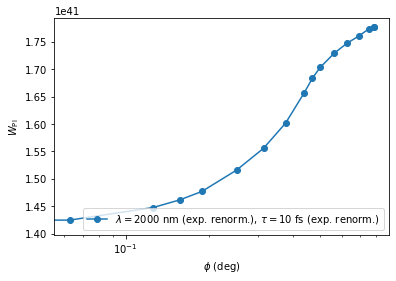

In [23]:
plt.figure()
plt.subplot(polar=False)
plt.semilogx(data2.PolarizationAngle, data2.Wpi_afterpulse, "-o", label=r"$\lambda=2000$ nm (exp. renorm.), $\tau=$10 fs (exp. renorm.)")
# plt.xlabel(r"$E_{peak}$ (V/m)")
plt.xlabel(r"$\phi$ (deg)")
plt.ylabel(r"$W_{\mathrm{PI}}$")
plt.legend(loc="best")
plt.show()

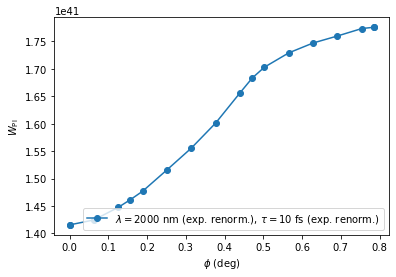

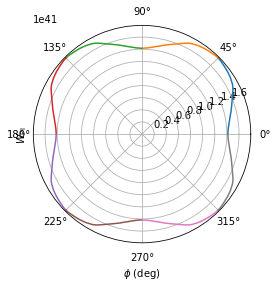

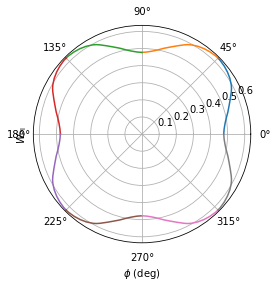

In [38]:
plt.figure()
plt.subplot(polar=False)
plt.plot(data2.PolarizationAngle, data2.Wpi_afterpulse, "-o", label=r"$\lambda=2000$ nm (exp. renorm.), $\tau=$10 fs (exp. renorm.)")
# plt.xlabel(r"$E_{peak}$ (V/m)")
plt.xlabel(r"$\phi$ (deg)")
plt.ylabel(r"$W_{\mathrm{PI}}$")
plt.legend(loc="best")
plt.show()


plt.figure()
plt.subplot(polar=True)
plt.plot(data2.PolarizationAngle, data2.Wpi_afterpulse, "-", label=r"$\lambda=2000$ nm (exp. renorm.), $\tau=$10 fs (exp. renorm.)")
plt.plot(2*45./180.*np.pi-data2.PolarizationAngle, data2.Wpi_afterpulse, "-")
plt.plot(data2.PolarizationAngle+2*45./180.*np.pi, data2.Wpi_afterpulse, "-")
plt.plot(4*45./180.*np.pi-data2.PolarizationAngle, data2.Wpi_afterpulse, "-")
plt.plot(data2.PolarizationAngle+4*45./180.*np.pi, data2.Wpi_afterpulse, "-")
plt.plot(6*45./180.*np.pi-data2.PolarizationAngle, data2.Wpi_afterpulse, "-")
plt.plot(data2.PolarizationAngle+6*45./180.*np.pi, data2.Wpi_afterpulse, "-")
plt.plot(8*45./180.*np.pi-data2.PolarizationAngle, data2.Wpi_afterpulse, "-")

# plt.xlabel(r"$E_{peak}$ (V/m)")
plt.xlabel(r"$\phi$ (deg)")
plt.ylabel(r"$W_{\mathrm{PI}}$")
# plt.legend(loc="best")
plt.show()

plt.figure()
plt.subplot(polar=True)
plt.plot(data2.PolarizationAngle, data2.Energy_afterpulse_eV, "-", label=r"$\lambda=2000$ nm (exp. renorm.), $\tau=$10 fs (exp. renorm.)")
plt.plot(2*45./180.*np.pi-data2.PolarizationAngle, data2.Energy_afterpulse_eV, "-")
plt.plot(data2.PolarizationAngle+2*45./180.*np.pi, data2.Energy_afterpulse_eV, "-")
plt.plot(4*45./180.*np.pi-data2.PolarizationAngle, data2.Energy_afterpulse_eV, "-")
plt.plot(data2.PolarizationAngle+4*45./180.*np.pi, data2.Energy_afterpulse_eV, "-")
plt.plot(6*45./180.*np.pi-data2.PolarizationAngle, data2.Energy_afterpulse_eV, "-")
plt.plot(data2.PolarizationAngle+6*45./180.*np.pi, data2.Energy_afterpulse_eV, "-")
plt.plot(8*45./180.*np.pi-data2.PolarizationAngle, data2.Energy_afterpulse_eV, "-")

# plt.xlabel(r"$E_{peak}$ (V/m)")
plt.xlabel(r"$\phi$ (deg)")
plt.ylabel(r"$W_{\mathrm{PI}}$")
# plt.legend(loc="best")
plt.show()

Now that data is available, let's try to build up an angle-dependent plot, like in Tancogne-Dejean et al., Physical review letters, 2016, 118, 087403. 

In [22]:
"""import glob
for JobID_id in datatmp.JobID:
    print(("JobID: "+str(JobID_id)))
    FileLookUp = "octopus-td." + str(JobID_id) + "*.log"
    # print(FileLookUp)
    ListFound = glob.glob("*/*/*/" + FileLookUp)
    # print(ListFound)
    entry=datatmp[datatmp.JobID==JobID_id]
    PolarizationAngle = np.array(entry.PolarizationAngle)[0] #reduces the content from DataFrame to Double
    print(PolarizationAngle * 180. / np.pi)
    """

'import glob\nfor JobID_id in datatmp.JobID:\n    print(("JobID: "+str(JobID_id)))\n    FileLookUp = "octopus-td." + str(JobID_id) + "*.log"\n    # print(FileLookUp)\n    ListFound = glob.glob("*/*/*/" + FileLookUp)\n    # print(ListFound)\n    entry=datatmp[datatmp.JobID==JobID_id]\n    PolarizationAngle = np.array(entry.PolarizationAngle)[0] #reduces the content from DataFrame to Double\n    print(PolarizationAngle * 180. / np.pi)\n    '